In [1]:
import matplotlib.pyplot as plt
import cv2
import pandas as pd
import os
import random
import numpy as np
import seaborn as sns
import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, Flatten, Input, MaxPooling2D,Dropout,BatchNormalization,Reshape
from keras import regularizers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

2026-01-26 19:46:11.560644: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1769456771.772977      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1769456771.832022      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1769456772.324398      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769456772.324448      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769456772.324455      24 computation_placer.cc:177] computation placer alr

In [2]:
# Impose seed for the reproducibility
seed = 42
keras.utils.set_random_seed(seed)
np.random.seed(seed)

In [3]:
#CNN input dimension
target = 32

In [4]:
# Paths of the folder of the images and labels, after use to access the files uploaded in the Input
path = "/kaggle/input/gtsrb-german-traffic-sign"
train_path = path + "/Train"
test_path = path + "/Test"
test_csv_path = path + "/Test.csv"


In [5]:
# List of images path to load them
img_list = []
label_train_list = []
folders = os.listdir(train_path)

for folder in folders:
    for img in os.listdir(train_path + "/"+folder):
        img_list.append  (train_path +  "/"+ folder+"/"+img)
        label_train_list.append(folder)                     

label_train_list = np.array(label_train_list, dtype=int)

In [6]:
# Dictionary used for the print of images with the number of the class and the corresponding name
label_name={
0: "Speed Limit 20",  
1: "Speed Limit 30",  
2: "Speed Limit 50",  
3: "Speed Limit 60",  
4: "Speed Limit 70",  
5: "Speed Limit 80",  
6: "End of a Speed Limit 80",  
7: "Speed Limit 100",  
8: "Speed Limit 120",  
9: "No overtaking",  
10: "No overtaking by trucks",  
11: "Crossroads",  
12: "Priority Road",  
13: "Give way",  
14: "Stop", 
15: "All vehicles prohibited in both directions",  
16: "No trucks",  
17: "No Entry",  
18: "Other Hazards",  
19: "Curve to left",  
20: "Curve to right",  
21: "Double curve, first to the left",  
22: "Uneven Road",  
23: "Slippery Road",  
24: "Road Narrows Near Side",  
25: "Roadworks",  
26: "Traffic lights",  
27: "No pedestrians",  
28: "Children",  
29: "Cycle Route",  
30: "Be careful in winter",  
31: "Wild animals",  
32: "No parking",  
33: "Turn right ahead",  
34: "Turn left ahead",  
35: "Ahead Only",  
36: "Proceed straight or turn right",  
37: "Proceed straight or turn left",  
38: "Pass onto right",  
39: "Pass onto left",  
40: "Roundabout",  
41: "No overtaking",  
42: "End of Truck Overtaking Prohibition",  
}

/tmp/ipykernel_24/4200997984.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(      x = df["actual_label"],


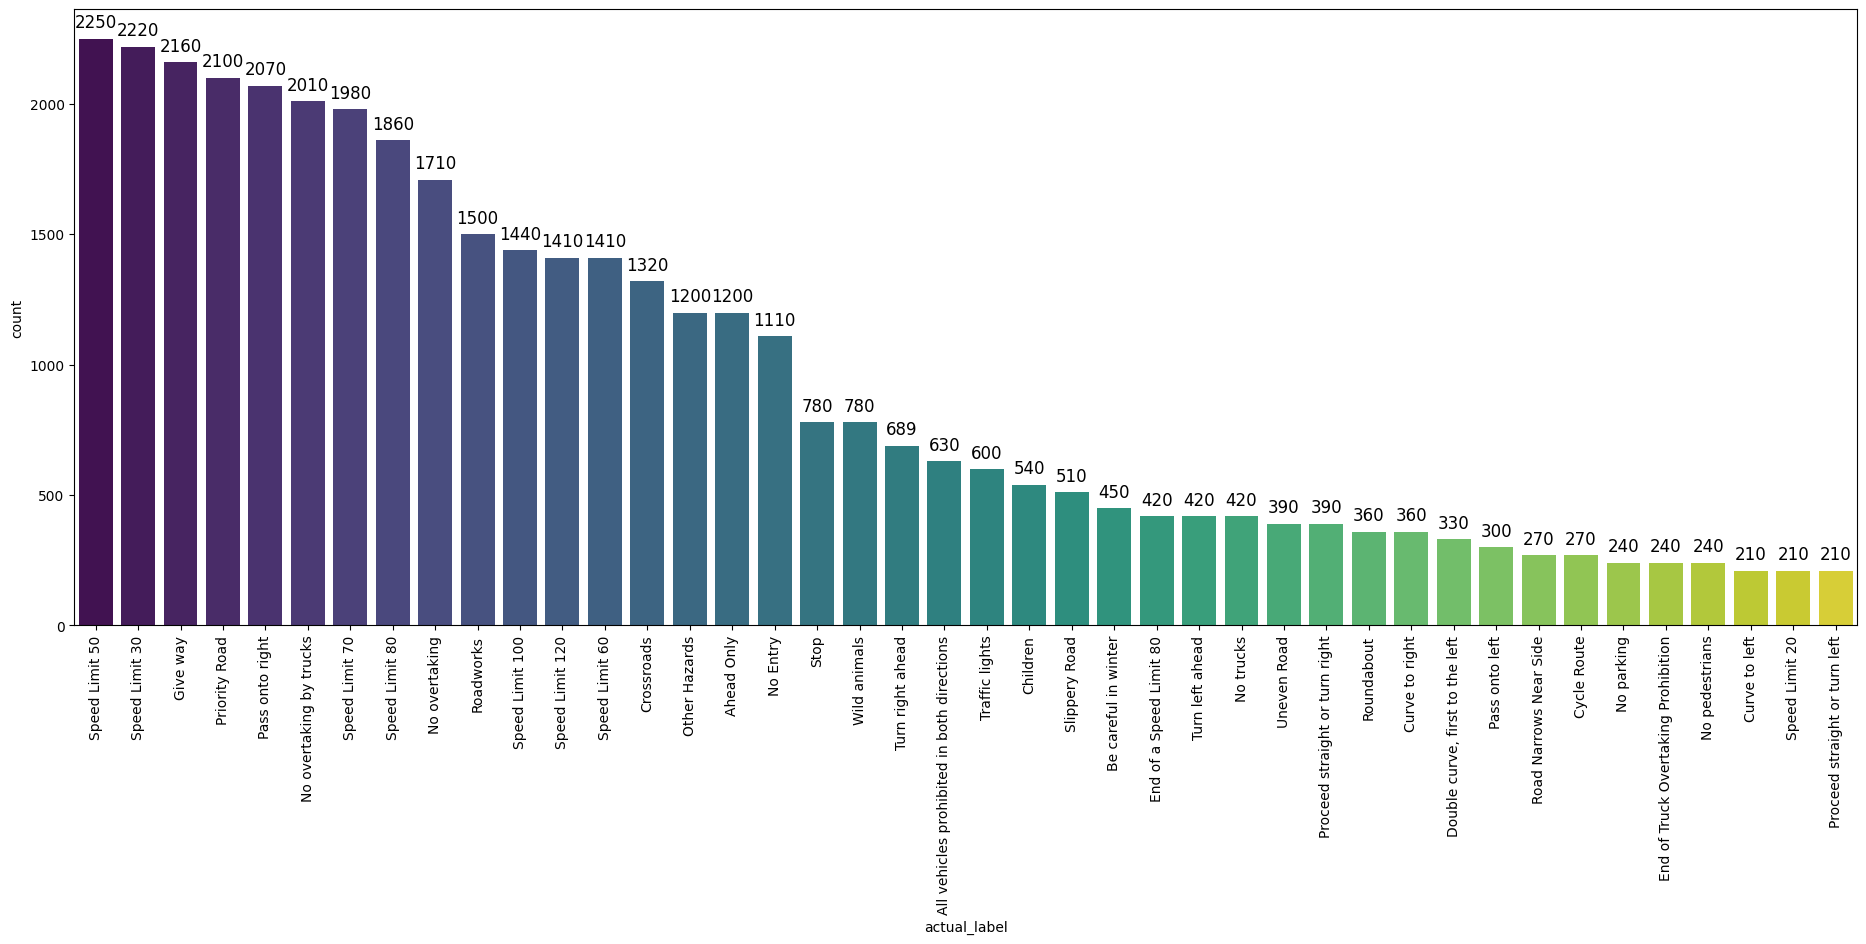

In [7]:
# Dataset visualization -> print of an histogram

df=pd.DataFrame({"img":img_list,"label":label_train_list})
df["label"]=df["label"].astype(int)                       
df["actual_label"]=df["label"].map(label_name)            

plt.figure(figsize=(23,8))                                

ax = sns.countplot(      x = df["actual_label"],          
                   palette = "viridis",                   
                     order = df['actual_label'].value_counts().index)

for p in ax.containers:
    ax.bar_label(p, fontsize=12, color='black', padding=5)           
    
plt.xticks(rotation=90);                                            

In [8]:
# Function for loading and resizing the images  
def process_image(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [target, target], method=tf.image.ResizeMethod.BILINEAR)
    img = img / 255.0  # Normalization
    return img, label

# Create a dataset with images and labels
dataset = tf.data.Dataset.from_tensor_slices((img_list, label_train_list))

# Pre-processing of the dataset
dataset = dataset.map(process_image, num_parallel_calls=tf.data.AUTOTUNE)

I0000 00:00:1769456786.697933      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [9]:
# Model definition

l2 = 0.0001

model=Sequential()
model.add(Input(shape=(target,target,3)))

model.add(Conv2D(64,kernel_size=(3,3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(l2)))
model.add(Conv2D(128,kernel_size=(3,3),activation='relu',padding='same', kernel_regularizer=regularizers.l2(l2)))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(BatchNormalization())
model.add(Dropout(0.25))

model.add(Conv2D(256,kernel_size=(3,3),activation='relu',padding='same', kernel_regularizer=regularizers.l2(l2)))
model.add(Conv2D(512,kernel_size=(3,3),activation='relu',padding='same', kernel_regularizer=regularizers.l2(l2)))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(BatchNormalization())
model.add(Dropout(0.25))

model.add(Flatten())

model.add(Dense(512,activation='relu'))
model.add(Dense(128,activation='relu'))

model.add(Dropout(0.2))
model.add(Dense(43,activation='softmax'))

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    16,777,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,402,475 (70.20 MB)

 Trainable params: 18,401,195 (70.19 MB)

 Non-trainable params: 1,280 (5.00 KB)

In [11]:
# Model compilation
opt      = keras.optimizers.Adam(learning_rate = 1e-3, ema_momentum=0.95)  
loss_fcn = keras.losses.SparseCategoricalCrossentropy()                    

model.compile(optimizer = opt,                                             
              loss      = loss_fcn,
              metrics   = ['accuracy'])

In [12]:
# Split of the dataset into train e validation set with a rate of 20%

split = 0.2

dataset_size = len(list(dataset)) 
train_size = int((1 - split) * dataset_size)

dataset = dataset.shuffle(buffer_size=dataset_size, seed=seed)

train_dataset = dataset.take(train_size)  
val_dataset = dataset.skip(train_size)    

In [13]:
data_augmentation = Sequential([
                      keras.layers.RandomRotation(0.05),
                      keras.layers.RandomTranslation(0.1,0.1),
                      keras.layers.RandomZoom(0.1)
])

In [14]:
batch_size = 128

train_dataset = train_dataset.map(lambda x, y: (data_augmentation(x, training=True), y))

# Data's batching and loading optimization
train_dataset = train_dataset.shuffle(buffer_size=int(train_dataset.cardinality()), seed=seed).batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)
val_dataset = val_dataset.batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

In [15]:
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, min_delta=0.005)
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, min_delta=0.001)

In [16]:
# Model Fit

n_epochs   = 50
history = model.fit(train_dataset,
                    validation_data = val_dataset,
                    epochs          = n_epochs,
                    batch_size      = batch_size,
                    callbacks       = [reduce_lr, early_stopping],
                    verbose         = 1   
                   )

Epoch 1/50


I0000 00:00:1769456897.250000      68 service.cc:152] XLA service 0x786d380156d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1769456897.250038      68 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1769456897.850076      68 cuda_dnn.cc:529] Loaded cuDNN version 91002


  5/246 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.0299 - loss: 7.4082

I0000 00:00:1769456905.383084      68 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


246/246 ━━━━━━━━━━━━━━━━━━━━ 73s 108ms/step - accuracy: 0.1925 - loss: 3.5952 - val_accuracy: 0.0393 - val_loss: 5.2832 - learning_rate: 0.0010
Epoch 2/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 52s 75ms/step - accuracy: 0.7780 - loss: 0.7799 - val_accuracy: 0.5569 - val_loss: 1.6249 - learning_rate: 0.0010
Epoch 3/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 54s 75ms/step - accuracy: 0.9331 - loss: 0.2984 - val_accuracy: 0.9749 - val_loss: 0.1540 - learning_rate: 0.0010
Epoch 4/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 53s 73ms/step - accuracy: 0.9559 - loss: 0.2271 - val_accuracy: 0.9909 - val_loss: 0.1078 - learning_rate: 0.0010
Epoch 5/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 54s 73ms/step - accuracy: 0.9662 - loss: 0.1950 - val_accuracy: 0.9829 - val_loss: 0.1503 - learning_rate: 0.0010
Epoch 6/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 55s 77ms/step - accuracy: 0.9751 - loss: 0.1711 - val_accuracy: 0.9929 - val_loss: 0.1066 - learning_rate: 0.0010
Epoch 7/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 54s 79ms/step - accuracy: 0.9854 - loss: 0.137

<class 'keras.src.callbacks.history.History'>
Accuracy:  0.9989798069000244
Validation Accuracy:  1.0
Loss:  0.05688232555985451
Validation Loss:  0.05350988730788231
Optimal Capacity:  16


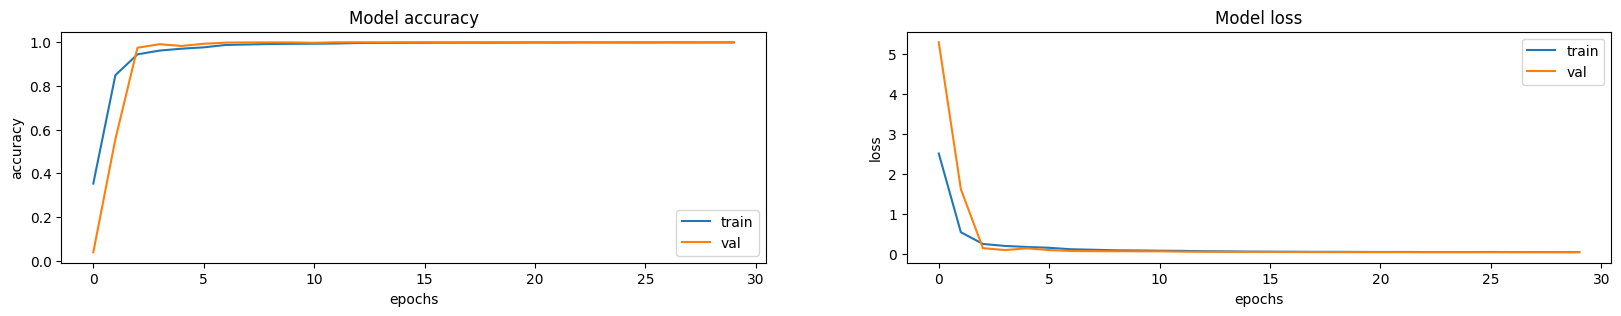

In [17]:
# Plot of the training graphs: accuracy and loss

print(type(history))
if type(history) != dict:
    history = history.history

plt.figure(figsize=(20, 3))
for i, metric in enumerate(["accuracy", "loss"]):
    plt.subplot(1, 2, i + 1)
    plt.plot(history[metric])
    plt.plot(history["val_" + metric])
    plt.title("Model {}".format(metric))
    plt.xlabel("epochs")
    plt.ylabel(metric)
    plt.legend(["train", "val"])

# print fo the training values
print("Accuracy: ", history["accuracy"][-1])
print("Validation Accuracy: ", history["val_accuracy"][-1])

print("Loss: ", history["loss"][-1])
print("Validation Loss: ", history["val_loss"][-1])

print("Optimal Capacity: ", np.argmax(history["val_accuracy"]) + 1)

In [18]:
# Obtaining test labels and correspective images' paths

test = pd.read_csv(test_csv_path)
test_labels=[]
test_path=[]
for i in range(len(test)):       
    test_labels.append(test["ClassId"][i])
    test_path.append(path +'/' + test["Path"][i])

test_labels = np.array(test_labels,dtype=int)     

In [19]:
# Create test set 
test_dataset = tf.data.Dataset.from_tensor_slices((test_path, test_labels))

# Pre-processing of test set
test_dataset = test_dataset.map(process_image, num_parallel_calls=tf.data.AUTOTUNE)

# Batch to speed-up the test
test_dataset = test_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

In [20]:
# Generate prediction of the model
predictions = model.predict(test_dataset)

# Get the class with the highest probability for each prediction
predictions = np.argmax(predictions, axis=-1)

# Compute the accuracy
accuracy = accuracy_score(test_labels, predictions)
print(f"Test Accuracy: {accuracy:.4f}")


99/99 ━━━━━━━━━━━━━━━━━━━━ 26s 256ms/step
Test Accuracy: 0.9846


In [21]:
# Extract the images and the labels
test_dataset_unbatched = test_dataset.unbatch()
x_test, y_test = zip(*test_dataset_unbatched)
x_test = np.array(x_test)
y_test = np.array(y_test)

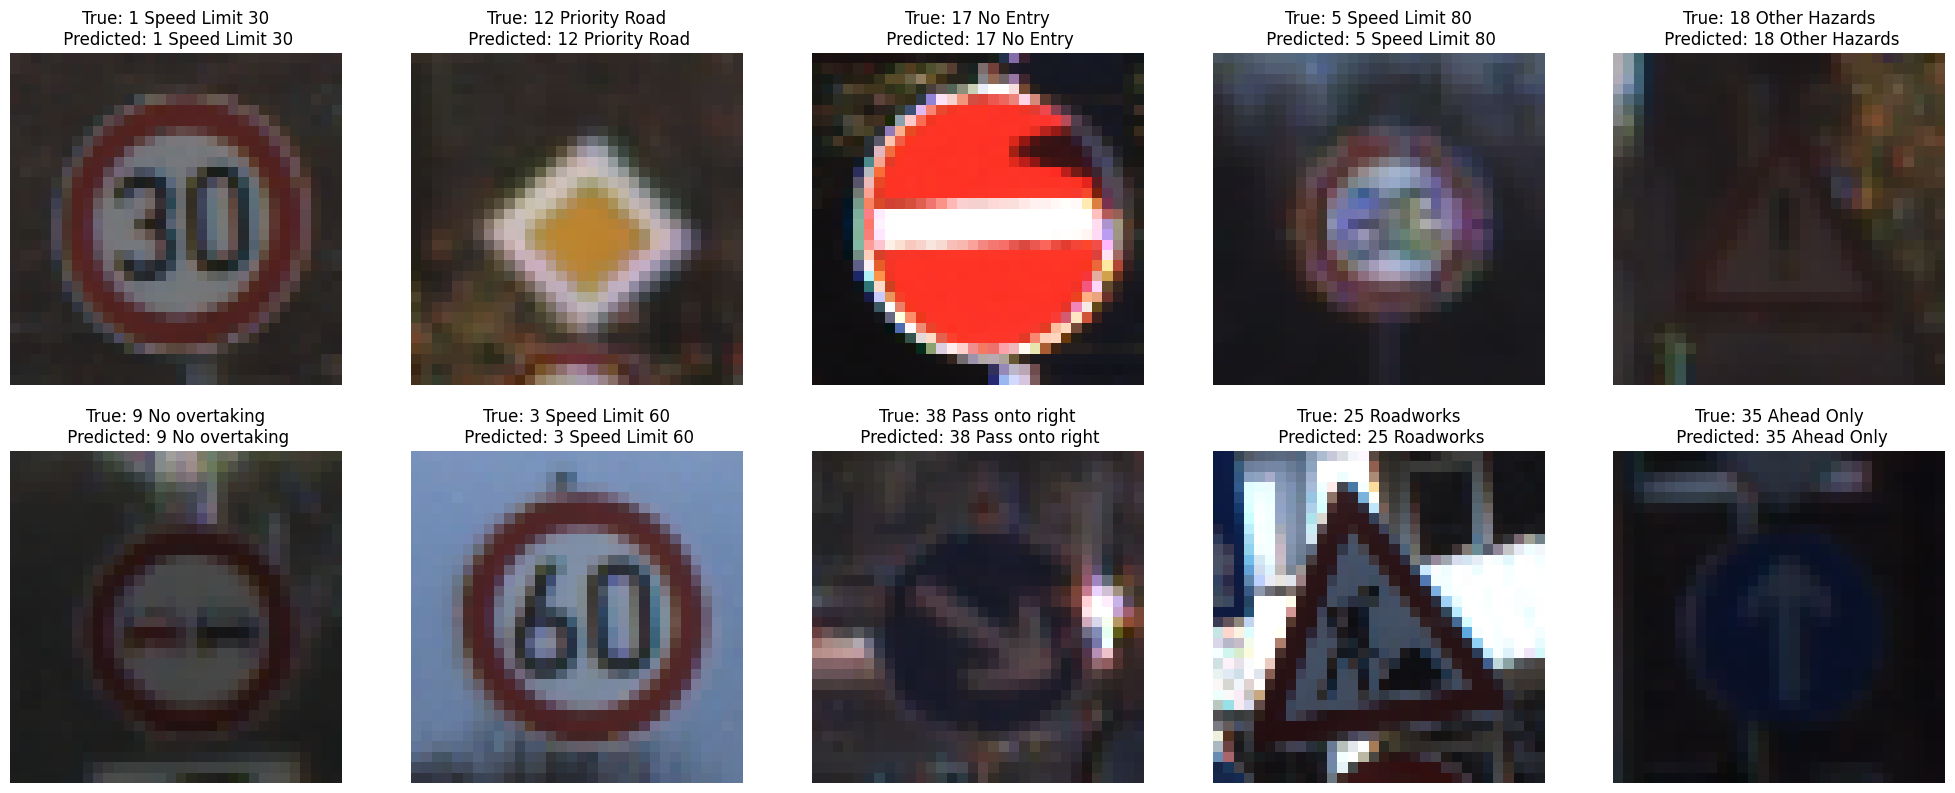

In [22]:
# Plot of 10 random images with corresponding prediction and true labels

plt.figure(figsize=(25, 25))

indices = random.sample(range(0, len(x_test)), 10)

j=0
for i in indices:
    j+=1
    plt.subplot(5, 5, j)
    plt.imshow(x_test[i])
    plt.title("True: {} {}\n Predicted: {} {}".format(y_test[i], label_name[y_test[i]],predictions[i], label_name[predictions[i]]) )
    plt.axis("off")